# Ứng dụng Tìm kiếm leo đồi đơn giản (Simple Hill Climbing) cho Bài toán Mê cung

Notebook này minh họa hành vi của thuật toán tìm kiếm cục bộ Leo đồi (Hill Climbing) khi áp dụng cho bài toán mê cung dạng chữ L (L-Maze).

## 1. Thiết lập môi trường và nạp dữ liệu

In [1]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("L_maze.txt", 
         "https://raw.githubusercontent.com/mhahsler/Introduction_to_Artificial_Intelligence/refs/heads/master/Local_Search/")
download("maze_helper.py", 
         "https://raw.githubusercontent.com/mhahsler/Introduction_to_Artificial_Intelligence/refs/heads/master/Local_Search/")

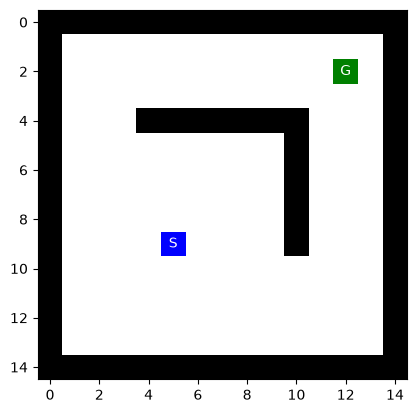

In [2]:
import numpy as np
import maze_helper as mh

f = open("L_maze.txt", "r")

maze_str = f.read()
maze = mh.parse_maze(maze_str)

mh.show_maze(maze)

## 2. Hàm hỗ trợ tìm kiếm (Search Helper)

Chúng ta cần định nghĩa hàm `expand` để sinh các trạng thái lân cận (neighbors) hợp lệ cho tìm kiếm cục bộ.

In [3]:
DIR2POS = {
    'N' : (-1, 0),
    'E' : ( 0, 1),
    'S' : ( 1, 0),
    'W' : ( 0,-1)
}

ORDER = None
RANDOMIZATION = None
DIRS = None 

# The order matters if RANDOMIZATION = False
# Note that: DFS works takes elements from the frontier in reverse order!
def set_order(order = "NESW", random = False, verbose = True):
    global RANDOMIZATION, DIR2POS, ORDER, DIRS
    
    RANDOMIZATION = random
    ORDER = [pos for pos in order]
    DIRS = [DIR2POS[dir] for dir in ORDER]
    
    if verbose:
        if RANDOMIZATION:
            print("Directions are checked at every step in random order.")
        else:
            print(f"Directions are checked in the order {ORDER}")
        
set_order("NESW", verbose = True)

Directions are checked in the order ['N', 'E', 'S', 'W']


In [4]:
def expand(maze, pos):
    """find available directions as a list of lists with elements [dir, (pos)]."""
    global RANDOMIZATION, DIRS, ORDER
       
    available = [[dir, pos] for dir, pos in zip(ORDER, np.add(pos, DIRS)) if mh.look(maze, pos) != "X"]
    if RANDOMIZATION: np.random.shuffle(available)
        
    return available

## 3. Thuật toán Leo đồi (Hill Climbing)

Chúng ta sử dụng khoảng cách Manhattan đến đích (Goal) làm hàm mục tiêu (Objective Function $h(n)$) với mục tiêu cần cực tiểu hóa (Minimization):
$$h(n) = |r_n - r_G| + |c_n - c_G|$$
Bước đi làm giảm $h(n)$ được xem là bước cải thiện.

In [5]:
# Manhattan distance h(n)
def manhattan(pos1, pos2):
    """returns the Manhattan distance between two positions"""
    return(np.sum(np.abs(np.subtract(pos1, pos2))))
    
print(manhattan([0,0], [1,1]))

2


In [6]:
def local_search(maze, vis = False, animation = False, verbose = False):
    if animation:
        maze_anim = []
    else:
        maze_anim = None
    
    # Local search starts here
    start_pos = mh.find_pos(maze, "S")
    goal_pos = mh.find_pos(maze, "G")

    current = start_pos
    current_obj = manhattan(current, goal_pos)

    while True:
        # find best neighbor
        neighbors = [n[1] for n in expand(maze, current)]
        obj = [manhattan(n, goal_pos) for n in neighbors]
        best_obj = min(obj)
        best_neighbor = neighbors[obj.index(best_obj)]

        if verbose:
            print("Current state:", current, "with obj", current_obj)
            print("Evaluating neighbors:\t", neighbors)
            print("Obj:\t\t\t", obj)


        # move there if it is an improvement or stop
        if best_obj < current_obj:
            current = best_neighbor
            current_obj = best_obj
            if verbose:
                print("Moving to:", current, "\n")
        else:
            if verbose:
                print("No better state in the neighborhood! Stopping.\n")
            break

        if animation:
            maze2 = maze.copy()
            maze2[current[0], current[1]] = "P"
            maze_anim.append(maze2)


    return { "solution" : current, "path" : None, "reached" : None, "maze_anim" : maze_anim }

## 4. Thực thi thuật toán và Quan sát

In [7]:
%time result = local_search(maze, animation = True, verbose = True)
result["solution"]

mh.animate_maze(result)

Current state: (np.int64(9), np.int64(5)) with obj 14
Evaluating neighbors:	 [array([8, 5]), array([9, 6]), array([10,  5]), array([9, 4])]
Obj:			 [np.int64(13), np.int64(13), np.int64(15), np.int64(15)]
Moving to: [8 5] 

Current state: [8 5] with obj 13
Evaluating neighbors:	 [array([7, 5]), array([8, 6]), array([9, 5]), array([8, 4])]
Obj:			 [np.int64(12), np.int64(12), np.int64(14), np.int64(14)]
Moving to: [7 5] 

Current state: [7 5] with obj 12
Evaluating neighbors:	 [array([6, 5]), array([7, 6]), array([8, 5]), array([7, 4])]
Obj:			 [np.int64(11), np.int64(11), np.int64(13), np.int64(13)]
Moving to: [6 5] 

Current state: [6 5] with obj 11
Evaluating neighbors:	 [array([5, 5]), array([6, 6]), array([7, 5]), array([6, 4])]
Obj:			 [np.int64(10), np.int64(10), np.int64(12), np.int64(12)]
Moving to: [5 5] 

Current state: [5 5] with obj 10
Evaluating neighbors:	 [array([5, 6]), array([6, 5]), array([5, 4])]
Obj:			 [np.int64(9), np.int64(11), np.int64(11)]
Moving to: [5 6] 

Cu

### Nhận xét quan trọng về kết quả:
- **Hiện tượng mắc kẹt tại cực trị cục bộ (Local Optimum):** Thuật toán dừng tại tọa độ `(5, 9)` với khoảng cách $h = 6$ mà **chưa thể đến được đích $G$** tại `(2, 12)` ($h=0$).
- **Nguyên nhân:** Bức tường chữ L nằm chắn giữa vị trí hiện tại và đích. Để vòng qua bức tường, thuật toán bắt buộc phải đi lùi lại hoặc rẽ sang hướng làm tăng khoảng cách Manhattan $h(n)$ tạm thời. Tuy nhiên, bản chất của Simple Hill Climbing là tham lam thuần túy (strictly greedy), chỉ chấp nhận bước đi làm giảm hàm mục tiêu ($h_{new} < h_{current}$). Do đó, tại `(5, 9)`, tất cả các ô lân cận hợp lệ đều có $h \ge 6$, khiến thuật toán kết luận đã đạt cực tiểu và dừng lại!

## 5. Thử nghiệm thay đổi thứ tự xét hướng và Lựa chọn ngẫu nhiên
Theo yêu cầu Bài 1 trong hướng dẫn thực hành, chúng ta khảo sát ảnh hưởng của thứ tự hướng ("NESW", "SENW", "WNES", v.v.) và chế độ ngẫu nhiên (`random=True`).

In [8]:
# Khảo sát các cấu hình thứ tự hướng khác nhau
orders_to_test = [
    ("NESW (Mặc định)", "NESW", False),
    ("SENW (Đảo hướng)", "SENW", False),
    ("WNES (Tây trước)", "WNES", False),
    ("ESWN (Đông trước)", "ESWN", False),
    ("Ngẫu nhiên 1 (Random=True)", "NESW", True),
    ("Ngẫu nhiên 2 (Random=True)", "NESW", True)
]

goal_pos = mh.find_pos(maze, 'G')
print("=== KẾT QUẢ THỬ NGHIỆM CÁC THỨ TỰ HƯỚNG ===")
for label, ord_str, rnd in orders_to_test:
    set_order(order=ord_str, random=rnd, verbose=False)
    res = local_search(maze, verbose=False)
    stopped = res['solution']
    reached = (stopped == goal_pos)
    h_val = manhattan(stopped, goal_pos)
    print(f"Cấu hình: {label:<24} | Dừng tại: {str(stopped):<8} | h(n): {h_val:<2} | Đến đích: {reached}")


=== KẾT QUẢ THỬ NGHIỆM CÁC THỨ TỰ HƯỚNG ===
Cấu hình: NESW (Mặc định)          | Dừng tại: [5 9]    | h(n): 6  | Đến đích: [False False]
Cấu hình: SENW (Đảo hướng)         | Dừng tại: [5 9]    | h(n): 6  | Đến đích: [False False]
Cấu hình: WNES (Tây trước)         | Dừng tại: [5 9]    | h(n): 6  | Đến đích: [False False]
Cấu hình: ESWN (Đông trước)        | Dừng tại: [5 9]    | h(n): 6  | Đến đích: [False False]
Cấu hình: Ngẫu nhiên 1 (Random=True) | Dừng tại: [5 9]    | h(n): 6  | Đến đích: [False False]
Cấu hình: Ngẫu nhiên 2 (Random=True) | Dừng tại: [5 9]    | h(n): 6  | Đến đích: [False False]


### Kết luận Bài 1:
Dù thay đổi thứ tự xét hướng hay cho phép lựa chọn ngẫu nhiên giữa các bước cải thiện, thuật toán Simple Hill Climbing vẫn bị chặn bởi bức tường chữ L và rơi vào bẫy cực tiểu cục bộ. Điều này làm nổi bật sự cần thiết của các giải thuật cải tiến hơn như **Random Restart** hoặc **Simulated Annealing** (cho phép chấp nhận bước đi tạm thời xấu hơn để vượt qua chướng ngại vật).